# 01 · EDA, giảm chiều và style guide

Công việc 1.4 (TV6). Sản phẩm: hình F2, F2b, F3, F4a, F4b, F4c, F4e; `docs/style_guide.md`; `src/viz.py`; mục 3.1 của báo cáo (`docs/report/3.1_eda.md`).

Chạy từ trên xuống. Cần đã chạy `make data` (tầng `cleansed` và `curated`). Mọi hình vẽ bằng `src/viz.py` và lưu hai bản `_report`, `_slide`.
Các ô **"Nhận xét"** ở cuối mỗi phần để trống (`…`): điền sau khi xem hình thật, không điền trước.

In [1]:
import os
from pathlib import Path

# Chuyển về thư mục gốc dự án để import được src/
while not (Path.cwd() / "src").is_dir():
    os.chdir("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import viz
from src.config import CURATED_DIR, METRICS_DIR, RANDOM_SEED
from src.load import load_golub

Xraw, samples = load_golub("cleansed")      # giá trị gốc (MAS4), có cột qc_outlier
Xl, _ = load_golub("curated")               # threshold [100, 16000] + log10: 72 x 7129
Xf = pd.read_parquet(CURATED_DIR / "X_log10_filtered.parquet")   # lọc Dudoit trên 72 mẫu: CHỈ cho EDA
Xf.index = Xf.index.astype(int)
assert Xl.index.equals(samples.index) and Xf.index.equals(samples.index), "lệch thứ tự mẫu"
print("Xraw", Xraw.shape, "| Xl", Xl.shape, "| Xf", Xf.shape, "| samples", samples.shape)

def show_and_save(stem, build):
    """Vẽ hình ở cả hai chế độ, lưu `_report` và `_slide`, hiển thị bản báo cáo."""
    for mode in viz.MODES:
        fig = build(mode)
        viz.save_figure(fig, stem, mode)
        if mode == "report":
            display(fig)
        plt.close(fig)

Xraw (72, 7129) | Xl (72, 7129) | Xf (72, 3571) | samples (72, 7)


## 1. Đơn biến và theo mẫu

### 1.1. Tỷ lệ lớp và cấu trúc mẫu
Bảng chéo đã kiểm ở `tests/test_load.py`; hiển thị lại để làm nền cho các hình sau. Thiết kế mẫu chi tiết (confounding, hình F1) thuộc công việc 1.3 (TV1).

In [2]:
print("Toàn bộ:", samples["class"].value_counts().to_dict())
pd.crosstab(samples["split"], samples["class"], margins=True, margins_name="Tổng")

Toàn bộ: {'ALL': 47, 'AML': 25}


class,ALL,AML,Tổng
split,,,
test,20,14,34
train,27,11,38
Tổng,47,25,72


In [3]:
pd.concat({"tissue": pd.crosstab(samples["class"], samples["tissue"]),
           "source": pd.crosstab(samples["class"], samples["source"]),
           "sex": pd.crosstab(samples["class"], samples["sex"].fillna("thiếu"))}, axis=1)

tissue    source                  sex          
          BM PB  CALGB CCG DFCI St-Jude   F   M thiếu
class                                                
ALL       41  6      0   0   44       3  20  21     6
AML       21  4     15   5    0       5   3   5    17

### 1.2. Vì sao cần log10? (F2)
Histogram mật độ của mọi giá trị biểu hiện (72 × 7129) trước và sau log10. Trước log dùng giá trị đã threshold [100, 16000] để so sánh công bằng. Độ lệch (skewness) ghi trên hình là **gộp mọi ô**; độ lệch **trung vị theo gen** nằm ở bảng bên dưới.

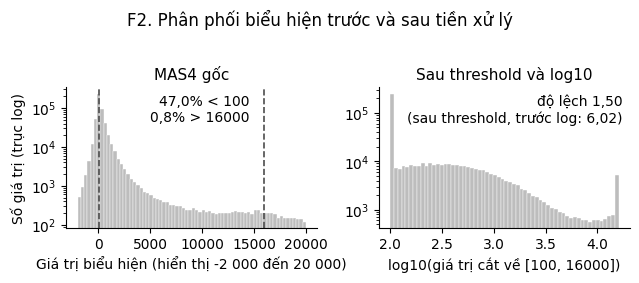

In [4]:
show_and_save("F02_hist_before_after_log", lambda m: viz.plot_hist_log(Xraw, Xl, mode=m))

In [5]:
S = viz.eda_summary(Xraw, Xl, Xf, samples)
pd.Series(S["skewness"]).round(3).to_frame("giá trị")

,giá trị
skew_median_gene_before,2.034
skew_median_gene_after,0.752
kurtosis_median_gene_before,4.888
kurtosis_median_gene_after,0.801
skew_pooled_before,6.021
skew_pooled_after,1.500


**Nhận xét F2:** 47,0% giá trị MAS4 nhỏ hơn 100 (28,7% là số âm, nhỏ nhất −28 400) và 0,8% lớn hơn 16 000, nên không thể lấy log trực tiếp và threshold [100, 16 000] là cần thiết. Độ lệch gộp giảm từ 6,02 (sau threshold, trước log) xuống 1,50 sau log10; trung vị theo gen giảm từ 2,03 xuống 0,75 (kurtosis dư từ 4,89 xuống 0,80). Log10 giảm mạnh độ lệch phải nhưng không đưa về phân phối chuẩn: còn một cột rất cao ở sàn log10 = 2 (các giá trị bị cắt về 100) và một cột nhỏ ở trần 4,2.

### 1.3. Chip lỗi hay khác biệt theo nguồn? (F3)
Boxplot 72 mẫu, sắp theo (tập, nguồn, lớp). Màu = nguồn, gạch chéo = AML. Cờ `qc_outlier` của TV2 (ADR-004) được chú thích trực tiếp; bảng dưới đối chiếu với tiêu chí khác (trung vị biểu hiện từng mẫu, modified z-score, ngưỡng 3,5).

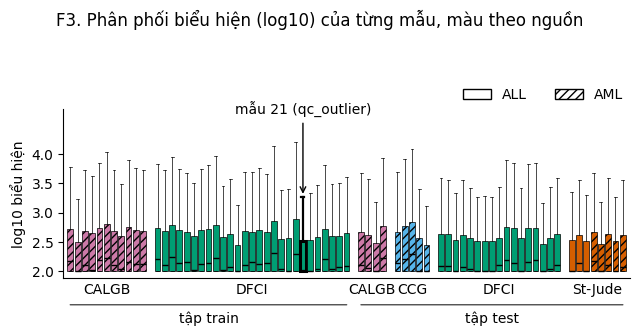

In [6]:
show_and_save("F03_box_per_sample", lambda m: viz.plot_box_per_sample(Xl, samples, mode=m))

In [7]:
out = viz.sample_median_outliers(Xl).join(samples[["split", "class", "source", "qc_outlier"]])
print("qc_outlier (TV2, theo tương quan giữa các mẫu):", S["qc_outlier_samples"])
print("Bất thường theo trung vị biểu hiện (|z| > 3,5):", S["median_based_outlier_samples"])
out.sort_values("modified_z", key=abs, ascending=False).head(8).round(3)

qc_outlier (TV2, theo tương quan giữa các mẫu): [21]
Bất thường theo trung vị biểu hiện (|z| > 3,5): []


,median_log10,modified_z,flag,split,class,source,qc_outlier
sample_id,,,,,,,
17,2.303,1.885,False,train,ALL,DFCI,False
20,2.297,1.824,False,train,ALL,DFCI,False
64,2.290,1.761,False,test,AML,CCG,False
3,2.248,1.363,False,train,ALL,DFCI,False
53,2.233,1.222,False,test,AML,CALGB,False
33,2.230,1.198,False,train,AML,CALGB,False
9,2.220,1.100,False,train,ALL,DFCI,False
63,2.210,1.000,False,test,AML,CCG,False


**Nhận xét F3:** Hộp của 72 mẫu nhìn chung tương tự nhau; 16/72 mẫu có trung vị đúng bằng mức sàn 2,0. Mẫu 21 (cờ `qc_outlier`, DFCI, ALL) có trung vị 2,0 như 15 mẫu kia, IQR thuộc nhóm thấp (thấp thứ 9/72) nhưng không khác hẳn các mẫu còn lại; tiêu chí modified z của trung vị biểu hiện không gắn cờ mẫu nào. Cờ của TV2 dựa trên tương quan giữa các mẫu (ADR-004) nên boxplot không đủ để loại mẫu; giữ nguyên mẫu 21. Theo nguồn: trung vị của trung vị mẫu là 2,04 ở St-Jude so với 2,10–2,13 ở CALGB, CCG, DFCI; IQR trung vị 0,58 so với 0,64–0,69. St-Jude thấp hơn nhẹ, phù hợp với quy trình lab khác (chú thích 23) nhưng chỉ có 8 mẫu nên chỉ để mô tả.

### 1.4. Phương sai của gen và lý do lọc (F2b)
Độ lệch chuẩn log10 của 7129 probe và kết quả lọc Dudoit (max/min > 5 và max − min > 500, tính trên thang gốc). Lọc trên cả 72 mẫu **chỉ dùng cho khám phá**; mô hình dùng `GeneFilter` trong Pipeline.

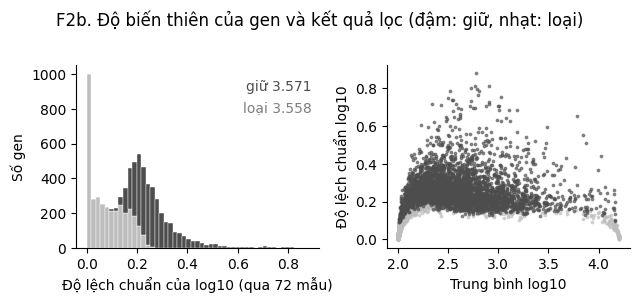

,giá trị
n_kept,3571.000000
n_removed,3558.000000
sd_log10_median_kept,0.244282
sd_log10_median_removed,0.067821


In [8]:
show_and_save("F02b_gene_variance", lambda m: viz.plot_gene_variance(Xl, mode=m))
pd.Series(S["gene_filter"]).to_frame("giá trị")

**Nhận xét F2b:** Giữ 3 571 gen (50,1%), loại 3 558 gen (khớp kế hoạch). SD log10 trung vị của gen bị loại là 0,068, của gen được giữ là 0,244. Gen bị loại dồn ở SD thấp, tập trung ở hai đầu mức biểu hiện (sát sàn 2,0 và sát trần 4,2), tức gần như không đổi giữa các mẫu nên lọc là hợp lý.

## 2. Đa biến và giảm chiều

PCA trên `X_log10_filtered`, z-score từng gen (EDA, không dùng để đánh giá mô hình).

### 2.1. Scree plot (F4a)

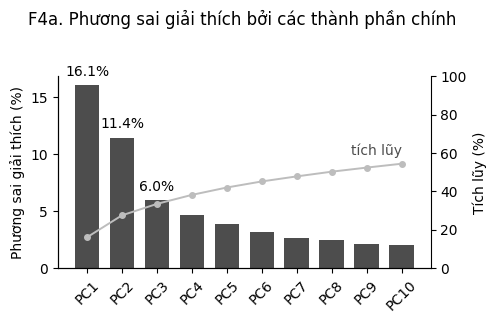

PC1 = 16.1% | PC1–PC2 = 27.5% | PC1–PC3 = 33.5%
Số PC để đạt 50% phương sai: 8 | 80%: 34


In [9]:
scores, ratio = viz.compute_pca(Xf, 10, RANDOM_SEED)
show_and_save("F04a_pca_scree", lambda m: viz.plot_scree(ratio, mode=m))
print(f"PC1 = {ratio[0]:.1%} | PC1–PC2 = {S['pca']['cumulative_pc1_pc2']:.1%} | PC1–PC3 = {S['pca']['cumulative_pc1_pc3']:.1%}")
print(f"Số PC để đạt 50% phương sai: {S['pca']['pcs_to_reach_50pct']} | 80%: {S['pca']['pcs_to_reach_80pct']}")

### 2.2. PCA PC1–PC2 theo lớp và nhóm con (F4b)
Chiều tô theo **nguồn và loại mô** (kiểm tra batch effect, H6) là F4d của TV1 (`02_design_batch.ipynb`), không lặp lại ở đây.

Quy ước đánh giá "PC tách ALL/AML" (định nghĩa chung của nhóm, dùng AUC Mann–Whitney của điểm số PC theo lớp):
**tốt** nếu AUC ≥ 0,9; **một phần** nếu 0,7 ≤ AUC < 0,9; **không** nếu AUC < 0,7. Đây là mô tả EDA, không phải kiểm định giả thuyết.

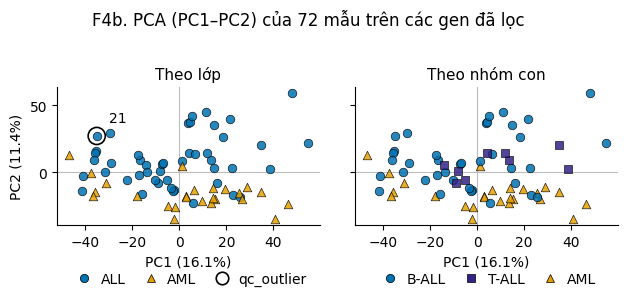

Silhouette theo lớp (PC1–PC2) = 0.140 | theo nhóm con = -0.023


,PC,auc,p_mannwhitney,đánh giá
0,PC1,0.5753,2.979398e-01,không
1,PC2,0.8911,5.665837e-08,một phần
2,PC3,0.8502,1.166196e-06,một phần
3,PC4,0.6349,6.164794e-02,không
4,PC5,0.5506,4.852708e-01,không


In [10]:
show_and_save("F04b_pca_by_class", lambda m: viz.plot_pca_by_class(scores, ratio, samples, mode=m))
verdict = lambda a: "tốt" if a >= 0.9 else "một phần" if a >= 0.7 else "không"
sep = pd.DataFrame(S["pca"]["class_separation_by_pc"])
sep["đánh giá"] = sep["auc"].map(verdict)
print(f"Silhouette theo lớp (PC1–PC2) = {S['pca']['silhouette_class_pc1_pc2']:.3f} | theo nhóm con = {S['pca']['silhouette_subtype_pc1_pc2']:.3f}")
sep

**Nhận xét F4b:** PC1 giải thích 16,1% phương sai nhưng không tách ALL/AML (AUC 0,58). PC2 tách **một phần** (AUC 0,89, sát ngưỡng 0,9; p = 5,7e-08) và PC3 cũng một phần (AUC 0,85). Trên mặt phẳng PC1–PC2, phần lớn AML nằm ở nửa dưới (PC2 thấp), ALL ở nửa trên, nhưng hai lớp chồng lấn ở vùng giữa-trái (silhouette theo lớp 0,14, thấp). T-ALL không tạo cụm riêng trên PC1–PC2 (silhouette theo nhóm con −0,02). Mẫu 21 nằm trong đám mây ALL, không tách xa các mẫu khác.

### 2.3. So sánh PCA, t-SNE và UMAP (F4c)
Cùng đầu vào (z-score), cùng seed. Khoảng cách giữa các cụm trên t-SNE và UMAP **không có ý nghĩa định lượng**; chỉ xem cụm có hình thành và có trùng lớp không.

/usr/local/lib/python3.12/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


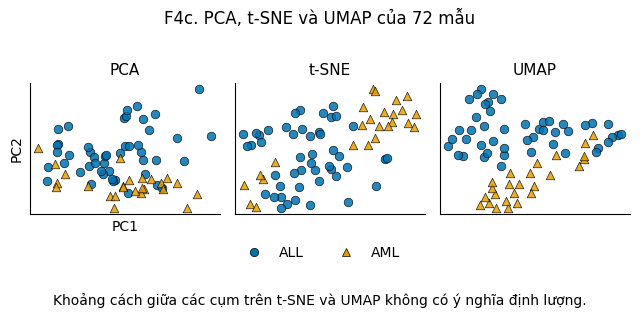

In [11]:
emb = viz.compute_embeddings(Xf, RANDOM_SEED)
show_and_save("F04c_tsne_umap", lambda m: viz.plot_embeddings(emb, samples, mode=m))

**Nhận xét F4c:** Cả ba phương pháp cho cùng bức tranh: AML tập trung thành vùng riêng nhưng chưa tách hẳn khỏi ALL (vài AML lẫn trong ALL). UMAP cho vùng AML gọn nhất, PCA lẫn nhiều nhất. Hình dạng cụm phụ thuộc seed và tham số (`perplexity` 15, `n_neighbors` 10), nên chỉ kết luận định tính, không so khoảng cách.

### 2.4. Tương quan giữa các mẫu và phân cụm phân cấp (F4e)
Pearson giữa 72 mẫu trên gen đã z-score; cây phân cấp theo khoảng cách 1 − r, liên kết average. Thanh trên: lớp; thanh trái: nguồn mẫu. Đường chéo (r = 1) bị bỏ khỏi thang màu.

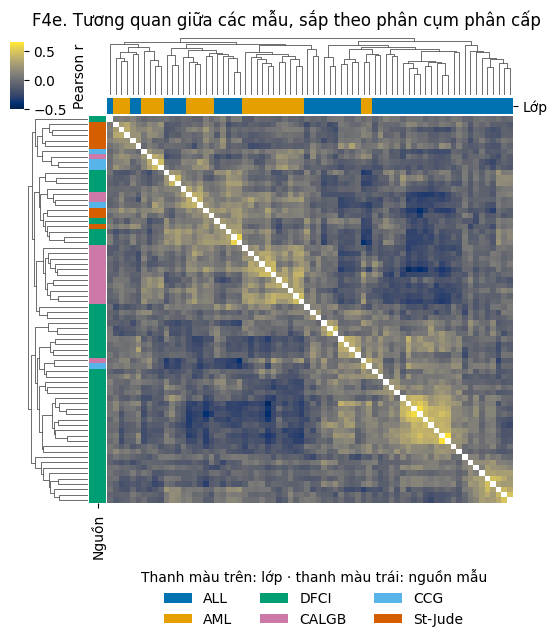

In [12]:
for mode in viz.MODES:
    fig = viz.plot_sample_correlation(Xf, samples, mode=mode)
    viz.save_figure(fig, "F04e_sample_correlation", mode)
    if mode == "report":
        display(fig)
    plt.close(fig)

**Nhận xét F4e:** Cắt cây ở k = 2: nhánh 1 có 38 mẫu (23 AML, 15 ALL), nhánh 2 có 34 mẫu (32 ALL, 2 AML); ARI so với lớp = 0,27 (chỉ để mô tả, phân cụm có hệ thống là việc 1.5 của TV5). Cả 9 T-ALL nằm ở nhánh 2. Cả 8 mẫu St-Jude (3 ALL, 5 AML) đều ở nhánh 1: dấu hiệu cần theo dõi khi phân tích lỗi (2.5), chưa kết luận vì TV1 không thấy khác biệt có ý nghĩa trên PC1–PC3 trong từng lớp (ADR-010). Mẫu 21 không nổi bật ở đây: tương quan trung vị với các mẫu khác trên gen đã z-score là −0,02 (hạng 52/72); thấp nhất là mẫu 69 (−0,08).

## 3. Nhận xét bắt buộc (điền số từ các ô trên) và lưu kết quả

In [13]:
sk, pca = S["skewness"], S["pca"]
print(f"Skewness trung vị của các gen: trước log = {sk['skew_median_gene_before']:.2f}, sau log = {sk['skew_median_gene_after']:.2f}")
print(f"PC1 giải thích {pca['explained_ratio'][0]:.1%} phương sai; PC1–PC2 tách ALL/AML: "
      + ", ".join(f"{r['PC']} AUC={r['auc']:.2f} ({verdict(r['auc'])})" for r in pca['class_separation_by_pc'][:3]))
print("Mẫu có vẻ bất thường trên boxplot/PCA:", S["median_based_outlier_samples"],
      "| cờ qc_outlier:", S["qc_outlier_samples"])

METRICS_DIR.mkdir(parents=True, exist_ok=True)
import json
(METRICS_DIR / "eda_summary.json").write_text(json.dumps(S, ensure_ascii=False, indent=2), encoding="utf-8")
print("Đã ghi", METRICS_DIR / "eda_summary.json")

Skewness trung vị của các gen: trước log = 2.03, sau log = 0.75
PC1 giải thích 16.1% phương sai; PC1–PC2 tách ALL/AML: PC1 AUC=0.58 (không), PC2 AUC=0.89 (một phần), PC3 AUC=0.85 (một phần)
Mẫu có vẻ bất thường trên boxplot/PCA: [] | cờ qc_outlier: [21]
Đã ghi /home/claude/realtest/results/metrics/eda_summary.json


**Tóm tắt cho báo cáo (mục 3.1):**
- Skewness trung vị của gen: trước log = 2,03, sau log = 0,75 (gộp mọi ô: 6,02 → 1,50); 47,0% giá trị < 100.
- PC1 = 16,1%, PC1–PC2 = 27,5%; PC1–PC2 tách ALL/AML **một phần** (PC2 AUC 0,89, PC3 0,85, PC1 0,58).
- Mẫu bất thường: mẫu 21 (`qc_outlier` của TV2) không nổi bật trên boxplot, PCA hay ma trận tương quan; giữ nguyên.
- Lưu ý cho giai đoạn 2: cả 8 mẫu St-Jude cùng nằm một nhánh phân cụm; phân tích lỗi (2.5) cần tách nhóm này.